**Q4 : le degré**

Le degré d'un nœud est son nombre de voisins. Dans ton graphe, on le calcule sur 2 réseaux :

Amitiés (IS_FRIEND, sans direction) : nombre d'amis par utilisateur.
Écoutes (LISTEN_TO, avec direction) : nombre d'artistes écoutés par utilisateur (degré sortant) et nombre d'auditeurs par artiste (degré entrant).

Connexion OK


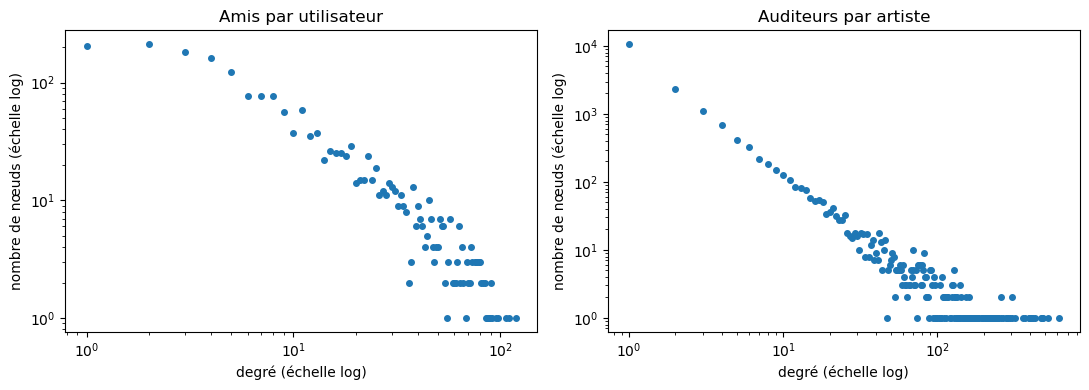

In [ ]:
import os
import pandas as pd
import matplotlib.pyplot as plt
from neo4j import GraphDatabase

from getpass import getpass
from neo4j import GraphDatabase

mdp = getpass("Mot de passe Neo4j : ")
driver = GraphDatabase.driver("bolt://localhost:7687", auth=("neo4j", mdp))
driver.verify_connectivity()
print("Connexion OK")

def run(q):
    with driver.session() as s:
        return pd.DataFrame(s.run(q).data())

friends = run("MATCH (u:User) RETURN COUNT { (u)-[:IS_FRIEND]-() } AS degree")
listeners = run("MATCH (a:Artist) RETURN COUNT { ()-[:LISTEN_TO]->(a) } AS degree")

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
for axis, df, titre in [(ax[0], friends, "Amis par utilisateur"),
                        (ax[1], listeners, "Auditeurs par artiste")]:
    counts = df["degree"].value_counts().sort_index()
    axis.loglog(counts.index, counts.values, "o", markersize=4)
    axis.set_xlabel("degré (échelle log)")
    axis.set_ylabel("nombre de nœuds (échelle log)")
    axis.set_title(titre)
plt.tight_layout()
plt.savefig("../results/figures/degree_distribution.png", dpi=150)
plt.show()

In [3]:
import networkx as nx
import numpy as np

# 1. Charger les amitiés (chaque paire une seule fois)
edges = run("""
MATCH (a:User)-[:IS_FRIEND]-(b:User)
WHERE a.userId < b.userId
RETURN a.userId AS a, b.userId AS b
""")
G = nx.from_pandas_edgelist(edges, "a", "b")
print("Nœuds :", G.number_of_nodes(), "| Arêtes :", G.number_of_edges())

# 2. Composantes connexes
comps = sorted(nx.connected_components(G), key=len, reverse=True)
print("Nombre de composantes :", len(comps))
print("Tailles des 5 plus grandes :", [len(c) for c in comps[:5]])

# 3. Plus grande composante : diamètre et distance moyenne
giant = G.subgraph(comps[0]).copy()
print("Taille de la plus grande :", giant.number_of_nodes())
print("Diamètre :", nx.diameter(giant))
print("Distance moyenne :", round(nx.average_shortest_path_length(giant), 2))

# 4. Comparaison avec un graphe aléatoire de même taille
n = giant.number_of_nodes()
k = 2 * giant.number_of_edges() / n
print("Distance attendue (graphe aléatoire) :", round(np.log(n) / np.log(k), 2))

Nœuds : 1892 | Arêtes : 12717
Nombre de composantes : 20
Tailles des 5 plus grandes : [1843, 7, 4, 3, 3]
Taille de la plus grande : 1843
Diamètre : 9
Distance moyenne : 3.52
Distance attendue (graphe aléatoire) : 2.87


**Q5 : distances**

On travaille sur le réseau d'amitié (User, IS_FRIEND), qui compte 1 892 nœuds et 12 717 arêtes. On y calcule :

le nombre de composantes connexes (groupes de gens reliés entre eux) et la taille de la plus grande,
le diamètre (le plus long des plus courts chemins),
la distance moyenne entre deux utilisateurs.

Le graphe est assez petit, donc on calcule tout exactement, sans échantillon. On utilise Python avec networkx (déjà installé), donc le plugin GDS n'est pas nécessaire ici.

In [4]:
from math import comb

n = G.number_of_nodes()
m = G.number_of_edges()

# Triangles réels
tri_par_noeud = nx.triangles(G)
triangles = sum(tri_par_noeud.values()) // 3
print("Triangles :", triangles)

# Clustering
print("Clustering moyen :", round(nx.average_clustering(G), 4))
print("Transitivité (globale) :", round(nx.transitivity(G), 4))

# Graphe aléatoire avec les mêmes n et m
p = m / comb(n, 2)
tri_attendus = comb(n, 3) * p**3
print("Densité p :", round(p, 5))
print("Triangles attendus (aléatoire) :", round(tri_attendus, 1))
print("Clustering attendu (aléatoire) :", round(p, 4))
print("Rapport réel / attendu :", round(triangles / tri_attendus, 1))

Triangles : 19690
Clustering moyen : 0.1865
Transitivité (globale) : 0.1338
Densité p : 0.00711
Triangles attendus (aléatoire) : 404.9
Clustering attendu (aléatoire) : 0.0071
Rapport réel / attendu : 48.6


**Q6 : triangles**

Un triangle : trois utilisateurs tous amis entre eux (A-B, B-C, C-A). Le coefficient de clustering d'un utilisateur est la part de ses amis qui sont aussi amis entre eux.

On travaille sur le réseau d'amitié entier (1 892 nœuds, 12 717 arêtes).

In [ ]:
#verification Vérifier l'hypothèse sur les hubs
#On compare le clustering des hubs (beaucoup d'amis) à celui des utilisateurs peu connectés. Nouvelle cellule, qui réutilise G :

import pandas as pd

deg = dict(G.degree())
clu = nx.clustering(G)

df = pd.DataFrame({"degre": deg, "clustering": clu})

# 1. Top 10 des hubs
top10 = df.sort_values("degre", ascending=False).head(10)
print("Clustering moyen des 10 plus gros hubs :", round(top10["clustering"].mean(), 4))
print("Clustering moyen de tout le réseau     :", round(df["clustering"].mean(), 4))

# 2. Clustering moyen par tranche de degré
df["tranche"] = pd.cut(df["degre"], bins=[0, 3, 10, 30, 200],
                       labels=["1-3 amis", "4-10", "11-30", "31+"])
print(df.groupby("tranche", observed=True)["clustering"].agg(["mean", "count"]).round(4))

Clustering moyen des 10 plus gros hubs : 0.1
Clustering moyen de tout le réseau     : 0.1865
            mean  count
tranche                
1-3 amis  0.1918    598
4-10      0.2220    609
11-30     0.1593    445
31+       0.1343    240


**Q7 : betweenness**

La betweenness d'un utilisateur mesure combien de plus courts chemins entre d'autres utilisateurs passent par lui. Un score élevé veut dire que c'est un pont : sans lui, le réseau se coupe en morceaux plus loin les uns des autres.

On la calcule sur le réseau d'amitié. Le graphe est petit, donc le calcul est exact et prend quelques secondes.

In [6]:
import pandas as pd
from scipy.stats import spearmanr

bet = nx.betweenness_centrality(G, normalized=True)
deg = dict(G.degree())
clu = nx.clustering(G)

df = pd.DataFrame({"betweenness": bet, "degre": deg, "clustering": clu})
df.index.name = "userId"

# Top 10 betweenness
top_bet = df.sort_values("betweenness", ascending=False).head(10)
print(top_bet.round(4))

# Top 10 degré
top_deg = df.sort_values("degre", ascending=False).head(10)

# Recouvrement des deux tops
communs = set(top_bet.index) & set(top_deg.index)
print("\nNœuds dans les deux top 10 :", len(communs), sorted(communs))

# Corrélation entre degré et betweenness
rho, _ = spearmanr(df["degre"], df["betweenness"])
print("Corrélation de Spearman (degré, betweenness) :", round(rho, 3))

        betweenness  degre  clustering
userId                                
1543         0.0665    119      0.0308
1281         0.0545    110      0.0339
831          0.0487    106      0.0509
1258         0.0430     86      0.0312
78           0.0293     81      0.0219
1213         0.0242     68      0.1010
1130         0.0238     57      0.0382
1503         0.0232     95      0.1091
298          0.0231     79      0.0542
1597         0.0218     70      0.0369

Nœuds dans les deux top 10 : 4 [831, 1281, 1503, 1543]
Corrélation de Spearman (degré, betweenness) : 0.825
